# 03 · Evaluate and explain

Two evaluations, always reported separately:
- **Lab** — PlantVillage valid split.
- **Field-proxy** — PlantDoc test split, remapped to the PlantVillage label space.

Then Grad-CAM, because the report needs to show the model looks at the leaf, not the background.


In [2]:
# --- Notebook 03: Drive Mount, Repo Setup, & Dataset Restoration ---
import os
import shutil
import subprocess
import sys
import zipfile
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')
DRIVE_RUN_DIR = Path("/content/drive/MyDrive/Final_Year_Project/PlantVillage_Disease_Classifier_Run")

# 2. Setup Repository Environment
REPO_NAME = "SKIT-DS-2023-2027-015"
REPO_URL = f"https://github.com/shankerjoshi/{REPO_NAME}.git"

if not os.path.exists(f"/content/{REPO_NAME}"):
    !git clone {REPO_URL} /content/{REPO_NAME}

%cd /content/{REPO_NAME}
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

!pip install -r requirements.txt -q
!pip install -q grad-cam captum

# 3. Restore Trained Model Weights from Drive
os.makedirs("runs", exist_ok=True)
drive_model = DRIVE_RUN_DIR / "best_disease_model.pt"
local_model = Path("runs/best.pt")

if drive_model.exists():
    shutil.copy2(drive_model, local_model)
    print(f"✓ Loaded trained model checkpoint from Google Drive: {local_model}")
elif local_model.exists():
    print("✓ Local model checkpoint runs/best.pt found.")
else:
    print("⚠️ Warning: best_disease_model.pt not found in Drive. Check runs/best.pt.")

# 4. Restore Clean Datasets from Drive to Colab Fast Disk
os.makedirs("data/fast", exist_ok=True)
os.makedirs("data/raw", exist_ok=True)

# A. Unzip clean PlantVillage fast dataset
drive_fast_zip = DRIVE_RUN_DIR / "data" / "fast" / "plantvillage_clean_fast.zip"
if drive_fast_zip.exists() and not os.path.exists("data/fast/plantvillage"):
    print(f"Extracting {drive_fast_zip.name} to local disk (~15 seconds)...")
    with zipfile.ZipFile(drive_fast_zip, 'r') as zf:
        zf.extractall("data/fast")
    print("✓ Clean PlantVillage dataset extracted to data/fast/plantvillage/")
elif os.path.exists("data/fast/plantvillage"):
    print("✓ data/fast/plantvillage/ already available locally.")

# B. Link or copy PlantDoc from Drive (Field Dataset for XAI)
drive_plantdoc = DRIVE_RUN_DIR / "data" / "raw" / "plantdoc"
local_plantdoc = Path("data/raw/plantdoc")
if drive_plantdoc.exists() and not local_plantdoc.exists():
    shutil.copytree(drive_plantdoc, local_plantdoc)
    print("✓ Mirrored PlantDoc field dataset to data/raw/plantdoc/")

# C. Link or copy Test set from Drive
drive_test = DRIVE_RUN_DIR / "data" / "raw" / "plantvillage" / "test" / "test"
local_test = Path("data/raw/plantvillage/test/test")
if drive_test.exists():
    local_test.mkdir(parents=True, exist_ok=True)
    for f in os.listdir(drive_test):
        if not (local_test / f).exists():
            shutil.copy2(drive_test / f, local_test / f)
    print(f"✓ Test set ready: {len(os.listdir(local_test))} images.")

# 5. Accelerator Check
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"\nEnvironment Ready | PyTorch: {torch.__version__} | Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'No GPU'})")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/SKIT-DS-2023-2027-015
✓ Loaded trained model checkpoint from Google Drive: runs/best.pt
Extracting plantvillage_clean_fast.zip to local disk (~15 seconds)...
✓ Clean PlantVillage dataset extracted to data/fast/plantvillage/
✓ Test set ready: 33 images.

Environment Ready | PyTorch: 2.14.1+cu130 | Device: cuda (Tesla T4)


In [3]:
# download plantdoc
# --- Download PlantDoc Field Dataset & Save to Drive ---
import os
import shutil
from pathlib import Path

# 1. Download PlantDoc via kagglehub
print("Downloading PlantDoc dataset via kagglehub...")
!pip install -q kagglehub

import kagglehub
pd_download = kagglehub.dataset_download("nirmalsankalana/plantdoc-dataset")
print(f"Downloaded PlantDoc to cache: {pd_download}")

# 2. Link into local data/raw/plantdoc
LOCAL_PD = Path("data/raw/plantdoc")
LOCAL_PD.mkdir(parents=True, exist_ok=True)

for item in Path(pd_download).iterdir():
    dest = LOCAL_PD / item.name
    if not dest.exists():
        if item.is_dir():
            shutil.copytree(item, dest)
        else:
            shutil.copy2(item, dest)

print(f"✓ Local PlantDoc directory ready: {[p.name for p in LOCAL_PD.iterdir()]}")

# 3. Mirror PlantDoc to Google Drive for future sessions
DRIVE_PD = Path("/content/drive/MyDrive/Final_Year_Project/PlantVillage_Disease_Classifier_Run/data/raw/plantdoc")
if not DRIVE_PD.exists():
    print(f"Backing up PlantDoc to Drive ({DRIVE_PD})...")
    shutil.copytree(LOCAL_PD, DRIVE_PD)
    print("✓ Mirrored PlantDoc to Google Drive!")
else:
    print("✓ PlantDoc already exists in Google Drive.")

100%|██████████| 896M/896M [00:08<00:00, 117MB/s]

Extracting files...


Downloaded PlantDoc to cache: /root/.cache/kagglehub/datasets/nirmalsankalana/plantdoc-dataset/versions/7
✓ Local PlantDoc directory ready: ['folder_renamer.py', 'train', 'test', 'file_renamer.py']
Backing up PlantDoc to Drive (/content/drive/MyDrive/Final_Year_Project/PlantVillage_Disease_Classifier_Run/data/raw/plantdoc)...
✓ Mirrored PlantDoc to Google Drive!


In [4]:
# 1. Lab Benchmark (Clean PlantVillage Validation Set)
!python -m src.evaluate --ckpt runs/best.pt --data data/fast/plantvillage/valid --tag plantvillage --out results

# 2. Real-World Field Benchmark (PlantDoc Test Set)
!python -m src.evaluate --ckpt runs/best.pt --data data/raw/plantdoc/test --field --tag plantdoc --out results

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
{
  "dataset": "plantvillage",
  "kind": "

In [5]:
import json, numpy as np, matplotlib.pyplot as plt
m_pv = json.load(open("results/metrics_plantvillage.json"))
m_pd = json.load(open("results/metrics_plantdoc.json"))
print(f"{'dataset':14s} {'acc':>7s} {'macroF1':>8s} {'top3':>7s} {'ECE':>7s}")
for m in (m_pv, m_pd):
    print(f"{m['dataset']:14s} {m['accuracy']:7.4f} {m['macro_f1']:8.4f} {m['top3_accuracy']:7.4f} {m['ece_15bin']:7.4f}")


dataset            acc  macroF1    top3     ECE
plantvillage    0.9986   0.9985  0.9999  0.0490
plantdoc        0.5556   0.2911  0.8333  0.1767


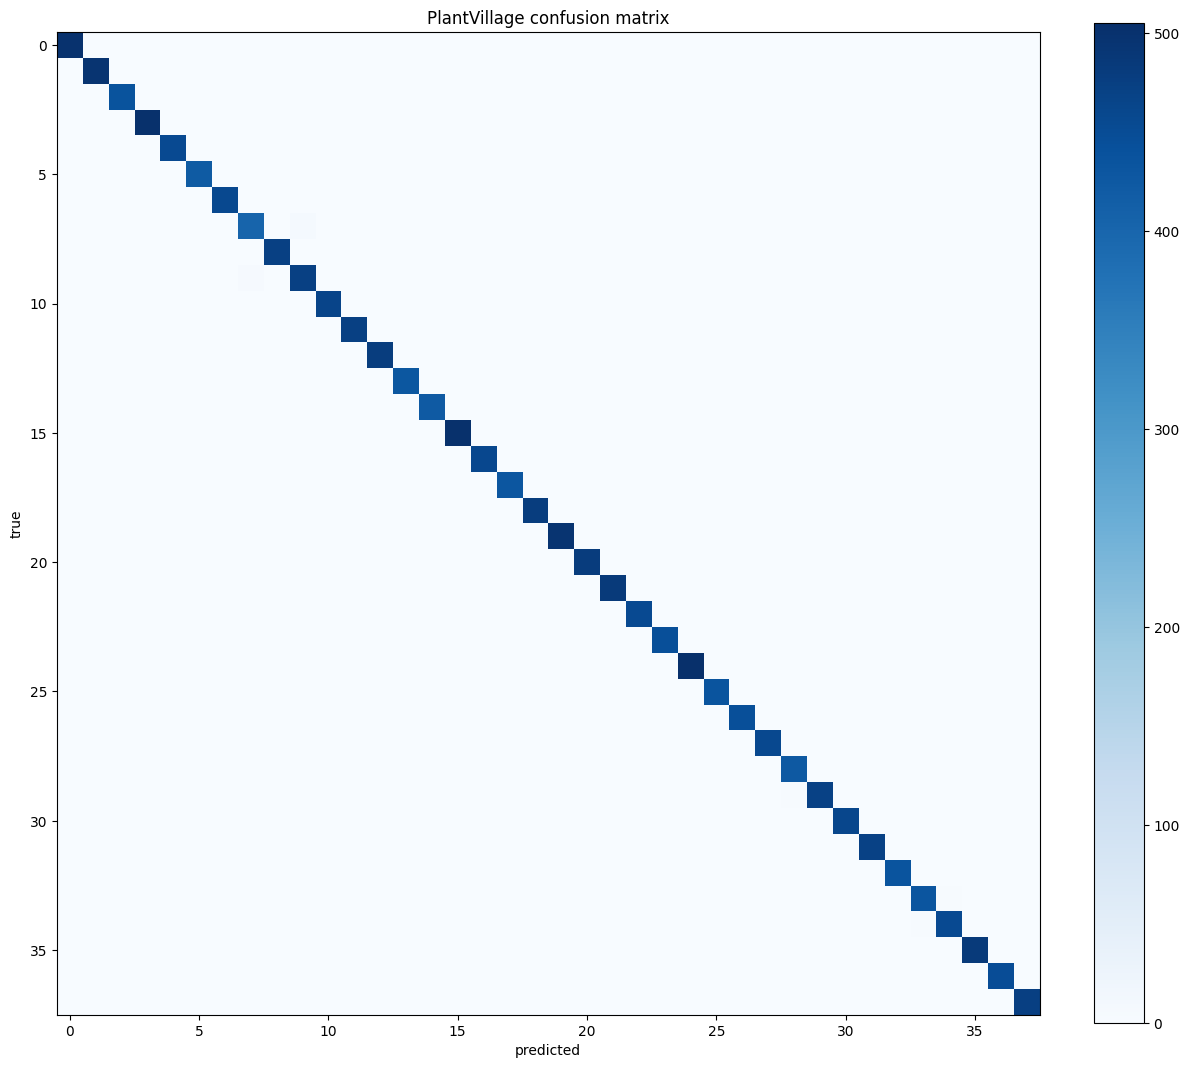

weakest classes:
  Corn_(maize)___Northern_Leaf_Blight           f1=0.987
  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot f1=0.988
  Tomato___Target_Spot                          f1=0.995
  Tomato___Early_blight                         f1=0.995
  Tomato___Spider_mites Two-spotted_spider_mite f1=0.995
  Tomato___Late_blight                          f1=0.997
  Tomato___Bacterial_spot                       f1=0.998
  Tomato___Septoria_leaf_spot                   f1=0.998


[None, None, None, None, None, None, None, None]

In [6]:
cm = np.load("results/cm_plantvillage.npy")
fig, ax = plt.subplots(figsize=(12, 12))
im = ax.imshow(cm, cmap="Blues")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("PlantVillage confusion matrix")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig("results_cm.png", dpi=110); plt.show()

per_class = sorted(m_pv["per_class"].items(), key=lambda kv: kv[1]["f1-score"])[:8]
print("weakest classes:"); [print(f"  {k:45s} f1={v['f1-score']:.3f}") for k, v in per_class]


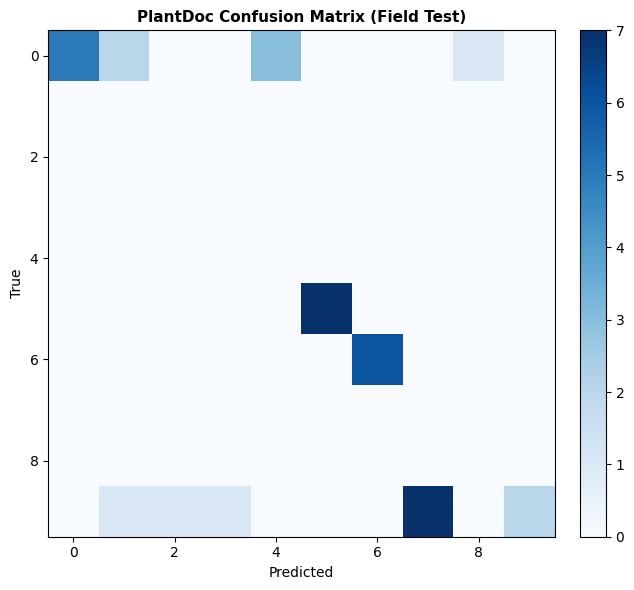


PlantDoc Weakest Classes (Field Domain Shift):
  Tomato___Septoria_leaf_spot                   f1=0.286 (support=12.0)
  Blueberry___healthy                           f1=0.625 (support=11.0)
  weighted avg                                  f1=0.647 (support=36.0)
  micro avg                                     f1=0.714 (support=36.0)
  macro avg                                     f1=0.728 (support=36.0)
  Raspberry___healthy                           f1=1.000 (support=7.0)
  Squash___Powdery_mildew                       f1=1.000 (support=6.0)


In [7]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Load PlantDoc Confusion Matrix
cm_pd = np.load("results/cm_plantdoc.npy")

# 2. Plot Compact Confusion Matrix
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_pd, cmap="Blues")
ax.set_xlabel("Predicted", fontsize=10)
ax.set_ylabel("True", fontsize=10)
ax.set_title("PlantDoc Confusion Matrix (Field Test)", fontsize=11, fontweight="bold")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig("results_cm_plantdoc.png", dpi=120)
plt.show()

# 3. Load Metrics and Display Weakest Classes
metrics_path = Path("results/metrics_plantdoc.json")
if metrics_path.exists():
    with open(metrics_path) as f:
        m_pd = json.load(f)

    per_class_pd = sorted(m_pd["per_class"].items(), key=lambda kv: kv[1]["f1-score"])[:8]
    print("\nPlantDoc Weakest Classes (Field Domain Shift):")
    for k, v in per_class_pd:
        print(f"  {k:45s} f1={v['f1-score']:.3f} (support={v.get('support', 'N/A')})")

wrote results/xai/gradcam_panel.jpg  (spot-check accuracy on these 12: 0.25)


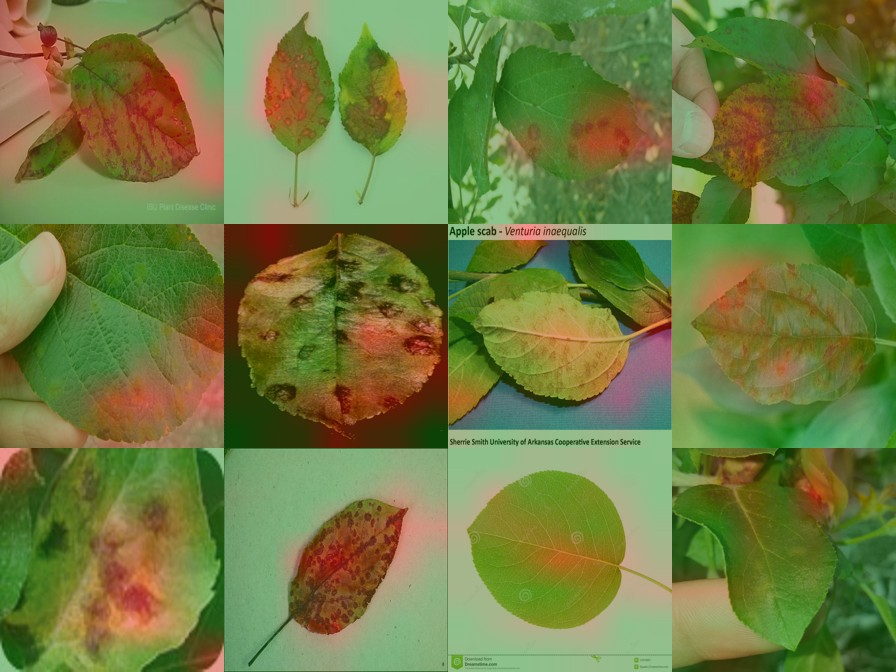

In [8]:
!python -m src.xai --ckpt runs/best.pt --data data/raw/plantdoc/test --n 12 --out results/xai
from IPython.display import Image as I
I("results/xai/gradcam_panel.jpg")


### Reading the Grad-CAM panel
If the heat sits on the background or the image border, the model learned the dataset, not the disease. That is the single most useful thing this panel can tell you, and it belongs in the report either way.
